In [1]:
!pip install -q tfds-nightly tensorflow matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 20.8 MB/s eta 0:00:00


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds

In [3]:
train = tfds.load('horses_or_humans', split='train', shuffle_files=True)
assert isinstance(train, tf.data.Dataset)
print(train)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/horses_or_humans/incomplete.YSDNGX_3.0.0/horses_or_humans-train.tfrecord-[…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/horses_or_humans/incomplete.YSDNGX_3.0.0/horses_or_humans-test.tfrecord-[0…

Dataset horses_or_humans downloaded and prepared to /root/tensorflow_datasets/horses_or_humans/3.0.0. Subsequent calls will reuse this data.
<_PrefetchDataset element_spec={'image': TensorSpec(shape=(300, 300, 3), dtype=tf.uint8, name=None), 'label': TensorSpec(shape=(), dtype=tf.int64, name=None)}>


In [4]:
test = tfds.load('horses_or_humans', split='test', shuffle_files=True)
assert isinstance(test, tf.data.Dataset)
print(test)

<_PrefetchDataset element_spec={'image': TensorSpec(shape=(300, 300, 3), dtype=tf.uint8, name=None), 'label': TensorSpec(shape=(), dtype=tf.int64, name=None)}>


In [5]:
tfds.features.FeaturesDict({
    'image': tfds.features.Image(shape=(300, 300, 3), dtype=tf.uint8),
    'label': tfds.features.ClassLabel(num_classes=2),
})

FeaturesDict({
    'image': Image(shape=(300, 300, 3), dtype=uint8),
    'label': ClassLabel(shape=(), dtype=int64, num_classes=2),
})

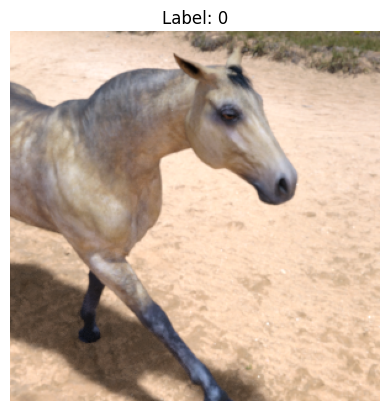

In [6]:
for example in train.take(2):
    image = example['image']
    label = example['label']

# Display the image
plt.imshow(image.numpy())
plt.title(f"Label: {label.numpy()}")
plt.axis('off')
plt.show()

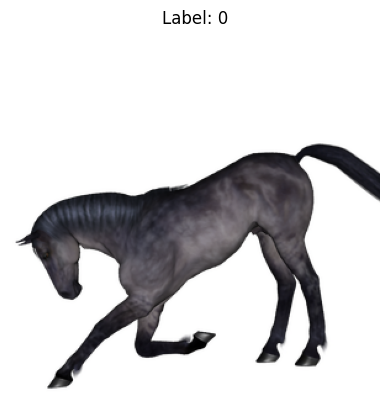

In [7]:
for example in test.take(2):
    image = example['image']
    label = example['label']

# Display the image
plt.imshow(image.numpy())
plt.title(f"Label: {label.numpy()}")
plt.axis('off')
plt.show()

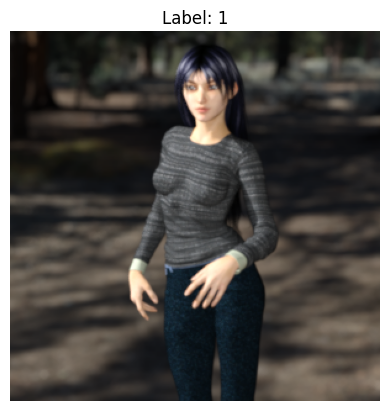

In [8]:
for example in train.take(9):
    image = example['image']
    label = example['label']

# Display the image
plt.imshow(image.numpy())
plt.title(f"Label: {label.numpy()}")
plt.axis('off')
plt.show()

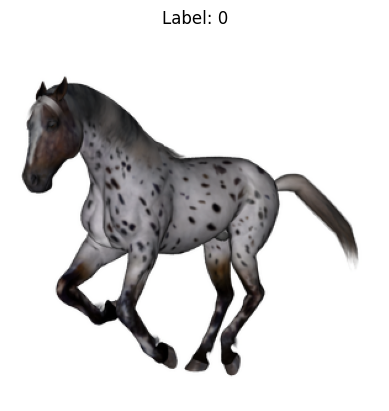

In [9]:
for example in test.take(9):
    image = example['image']
    label = example['label']

# Display the image
plt.imshow(image.numpy())
plt.title(f"Label: {label.numpy()}")
plt.axis('off')
plt.show()

In [10]:
label_1_count = 0
for example in train:
    if example['label'].numpy() == 1:
        label_1_count += 1

print(f"Número total de imagens com o rótulo 1(humanos) no dataset de treino: {label_1_count}")

Número total de imagens com o rótulo 1(humanos) no dataset de treino: 527


In [11]:
label_0_count = 0
for example in train:
    if example['label'].numpy() == 0:
        label_0_count += 1

print(f"Número total de imagens com o rótulo 0(cavalos) no dataset de treino: {label_0_count}")

Número total de imagens com o rótulo 0(cavalos) no dataset de treino: 500


In [12]:
from tensorflow.keras.models import Sequential


In [13]:
train

<_PrefetchDataset element_spec={'image': TensorSpec(shape=(300, 300, 3), dtype=tf.uint8, name=None), 'label': TensorSpec(shape=(), dtype=tf.int64, name=None)}>

In [14]:
from tensorflow import keras
from tensorflow.keras import layers

# Cria um modelo sequencial (as camadas são empilhadas uma após a outra)
model = keras.Sequential([

    # Normaliza os valores dos pixels da imagem
    # Converte de [0, 255] para [0, 1], o que ajuda no treinamento
    layers.Rescaling(1./255),

    # Primeira camada convolucional
    # 16 filtros (kernels) de tamanho 3x3
    # padding='same' mantém o tamanho da imagem
    # activation='relu' introduz não-linearidade
    layers.Conv2D(16, 3, padding='same', activation='relu'),

    # Reduz a dimensionalidade espacial (downsampling)
    # Mantém as features mais importantes
    layers.MaxPooling2D(),

    # Segunda camada convolucional
    # Aumenta o número de filtros para 32 (aprende padrões mais complexos)
    layers.Conv2D(32, 3, padding='same', activation='relu'),

    # Novo downsampling para reduzir custo computacional
    layers.MaxPooling2D(),

    # Terceira camada convolucional
    # 64 filtros para capturar padrões ainda mais abstratos
    layers.Conv2D(64, 3, padding='same', activation='relu'),

    # Reduz novamente o tamanho das features
    layers.MaxPooling2D(),

    # Transforma o mapa de features 2D em um vetor 1D
    # Necessário para conectar às camadas densas
    layers.Flatten(),

    # Dropout de 20%
    # Desliga neurônios aleatoriamente durante o treino
    # Ajuda a evitar overfitting
    layers.Dropout(0.2),

    # Camada totalmente conectada com 128 neurônios
    # Aprende combinações globais das features extraídas
    layers.Dense(128),

    # Camada de saída com 2 neurônios
    # Cada neurônio representa uma classe
    # (ex: classe 0 e classe 1)
    layers.Dense(units=2)
])


In [15]:
model.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy'])

In [ ]:
def format_example(element):
  image = element['image']
  label = element['label']
  return image, label

BATCH_SIZE = 32
train_ds = train.map(format_example).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = test.map(format_example).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)



epochs = 2
model.fit(train_ds, epochs=epochs, verbose=1)

Epoch 1/2
 7/33 ━━━━━━━━━━━━━━━━━━━━ 1:26 3s/step - accuracy: 0.5571 - loss: 10.9440

In [ ]:

epochs = 2
model.fit(test_ds, epochs=epochs, verbose=1)